<center> <h1><b>Leveraging Sentiment Analysis for maximizing customer satisfaction: An Industrial Engineering Approach <b> <h1>
<center>





Dresden optics is an eye glass and eye prescriptive company that helps in providing sustainable glasses for people both for medical and recreational purposes. The aim of this project is to analyze feedback from the customers and use those insights to optimize resources for maximum customer satisfaction. The objectives/steps include:

# **Outline of project**
 1. **Problem Identification and Scope Definition:** our problem at hand is to look for ways to optimize customer satisfaction. In this stage we get all necessary information about the company and data on the customers.
 2. **Data Collection and Preprocessing:** This involves cleaning and standardization of data.
 4. **Text Presentation:**
TF-IDF (Term Frequency-Inverse Document Frequency): Bag of Words, with also takes into account how important a word is in the document compared to the corpus as a whole.
Word2Vec, GloVe, FastText
 3. **Sentiment Analysis:** This is to identify and classify a customer into satisfied, neutral, and unsatisfied.
 4. **Topic modelling:** Evaluating each comment and identify the main topics the customers are bringing up in comments (This will include complains and what makes them happy)
 5. **Exploratory data analysis:** explore the data used.
 6. **Risk assessment:** Evaluate the complaints and praises from customers. Assign values on how much each topic influences the general sentiment of customers.
 7. **Optimization of customer Satisfaction:** Considering each topic as variables and considering possible constraints in the company resources, we optimize the general sentiment of each region and general sentiment of the company.

# **Problem Identification and Scope Definition**

## **Buisness problem**
Dresden optics as a company wants to know about customer satisfaction levles and major topicas of interest to be able to provide better services and optimize customer satisfacton.
## **Assumption**
Under this project we will consider the following asssumptions:
1. Customer comments are accurate and a reflection of how they feel.
2. The more a topic is being mentioned the more it is important in the eyes of the customers


##**Research Questions**
research will look on a general level, on a region based level and on a shop based level.
1. Based on the comments given what are the what are the sentiment of each.
2. Based on each comments what are the topics beind described is it being descriped in a postive or negative light?
3.  How can we preioritize resources that bring more customer satisfactions

Note: we will not only be looking at the "Comments" column we will also look at "the Why did you shop at Dresden?","Where did you hear about us?".

##**Approach**
We will use Machine learning tools to extract customer sentiments and topics then we use interger programming to prioritize each resource.



# **Steps**


1.  Data collection and cleaning
2.  Exploratory data analysis
3.  Sentimental analysis
4. Text classification
5. Case studies (including regional and general)



# **Data collection and cleaning**
In this step we collected data from survey reponses and combined it to a single excel sheet for analysis. we will also clean the data to a more understandable form that can be easily  analyzed accurately.

In [ ]:
#we will start by importing all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')
import nltk
import pandas as pd
import plotly.graph_objects as go

In [ ]:
!pip install tqdm
from tqdm import *

In [ ]:
!pip install transformers

In [ ]:
import transformers

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from scipy.special import softmax


In [ ]:
!pip install -U kaleido


In [ ]:
MODEL = f"cardiffnlp/twitter-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForSequenceClassification.from_pretrained(MODEL)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF


In [ ]:
#we will now import the data
df = pd.read_excel('/content/Final.xlsx')
df.head()

,Id,Location_id,Country,Where did you hear about us?,Why did you shop at Dresden?,comments,Satisfaction level,How likely are you to recommend?
0,1,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0
1,2,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0
2,3,NILL,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0
3,4,NILL,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0
4,5,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0


In [ ]:
#checks to understand the data
df.columns = df.columns.str.strip()
print(df.columns)


Index(['Id', 'Location_id', 'Country', 'Where did you hear about us?',
       'Why did you shop at Dresden?', 'comments', 'Satisfaction level',
       'How likely are you to recommend?'],
      dtype='object')


In [ ]:
#display the row X column counts of the data
df.shape

(2014, 8)

In [ ]:
#information  on each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2014 entries, 0 to 2013
Data columns (total 8 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Id                                2014 non-null   int64  
 1   Location_id                       2014 non-null   object 
 2   Country                           2014 non-null   object 
 3   Where did you hear about us?      2014 non-null   object 
 4   Why did you shop at Dresden?      1999 non-null   object 
 5   comments                          1568 non-null   object 
 6   Satisfaction level                2010 non-null   float64
 7   How likely are you to recommend?  1969 non-null   float64
dtypes: float64(2), int64(1), object(5)
memory usage: 126.0+ KB


In [ ]:
#convert columns to appropriate type in this case "string"
df["comments"] = df["comments"].astype(str)
df["Why did you shop at Dresden?"] = df["Why did you shop at Dresden?"].astype(str)
df["Where did you hear about us?"] = df["Where did you hear about us?"].astype(str)

In [ ]:
#renmae columns to ease use
new_column_names = {'Where did you hear about us?': 'About', 'Why did you shop at Dresden?': 'Favour' , "How likely are you to recommend?" : "recommendation_level"}
df =df.rename(columns=new_column_names)


In [ ]:
# Check for duplicates in the entire datasheet
duplicates_df = df[df.duplicated(keep=False)]

if duplicates_df.empty:
    print("No duplicates found in the datasheet.")
else:
    print("Duplicates found in the datasheet:")
    print(duplicates_df)


No duplicates found in the datasheet.


In [ ]:
# Check for null values in the entire datasheet
null_values = df.isnull().sum()
# Display the count of null values for each column
print("Null values in the datasheet:")
print(null_values)

Null values in the datasheet:
Id                       0
Location_id              0
Country                  0
About                    0
Favour                   0
comments                 0
Satisfaction level       4
recommendation_level    45
dtype: int64


In [ ]:
#drop all null records
df = df.dropna()

In [ ]:
# Check for null values in the entire datasheet
null_values = df.isnull().sum()
# Display the count of null values for each column
print("Null values in the datasheet:")
print(null_values)

Null values in the datasheet:
Id                      0
Location_id             0
Country                 0
About                   0
Favour                  0
comments                0
Satisfaction level      0
recommendation_level    0
dtype: int64


In [ ]:
#check shape
df.shape

(1965, 8)

In [ ]:
#drop any unforseen nulls in comments , favour and abount columns ,
df.dropna(subset=['comments','Favour','About'], inplace=True)


In [ ]:
#reset the index,
df.reset_index(drop=True, inplace=True)


In [ ]:
# check shape again
df.shape

(1965, 8)

In [ ]:
#check first 5 rows
df.head()

,Id,Location_id,Country,About,Favour,comments,Satisfaction level,recommendation_level
0,1,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0
1,2,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0
2,3,NILL,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0
3,4,NILL,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0
4,5,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0


# **Exploratory Data analysis**
In this section we try to look to understand the chracteristics of the data to help us get a better understanding of the data. The main aim of exploratory data analysis to to have a broad over view of the entire data set being worked on.

In [ ]:
df.head()

,Id,Location_id,Country,About,Favour,comments,Satisfaction level,recommendation_level
0,1,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0
1,2,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0
2,3,NILL,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0
3,4,NILL,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0
4,5,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0


In [ ]:
df.describe

<bound method NDFrame.describe of         Id Location_id    Country                                  About  \
0        1        NILL  Australia   Recommended by a friend or colleague   
1        2        NILL  Australia   Recommended by a friend or colleague   
2        3        NILL  Australia  I’m a Dresden Vision customer already   
3        4        NILL  Australia  I’m a Dresden Vision customer already   
4        5        NILL  Australia   Recommended by a friend or colleague   
...    ...         ...        ...                                    ...   
1960  2010           6  Australia                                   NILL   
1961  2011           4     Canada                                   NILL   
1962  2012           5     Canada                                   NILL   
1963  2013           2  Australia                                   NILL   
1964  2014           4     Canada                                   NILL   

                                                 Favo

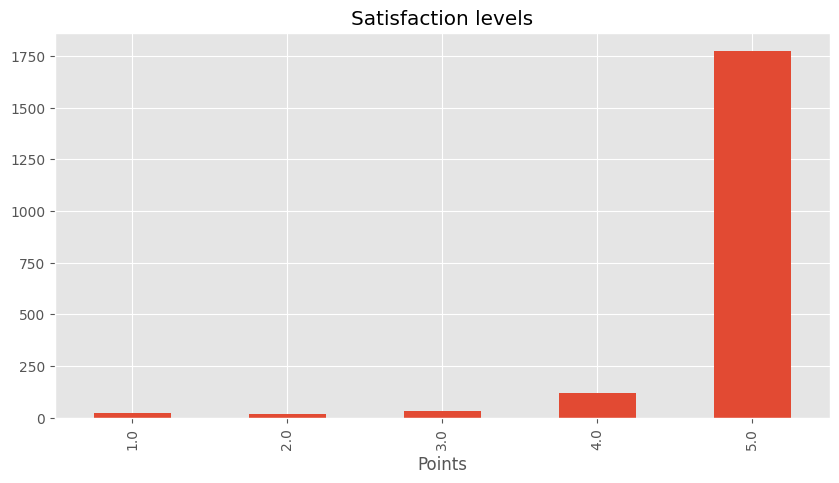

In [ ]:

#the amount of customers that are satisfied with the services on each level

ax = df['Satisfaction level'].value_counts().sort_index() \
    .plot(kind='bar',
          title='Satisfaction levels',
          figsize=(10, 5))
ax.set_xlabel('Points')
# Save the plot as a PNG image
plt.savefig('Satisfaction levels.png')
plt.show()




In [ ]:
#Calculate value counts and percentages
value_counts = df['Satisfaction level'].value_counts()
total_entries = len(df)
percentages = (value_counts / total_entries) * 100

# Print value counts and percentages
for category, count in value_counts.items():
    percentage = percentages[category]
    print(f"Category: {category} | Count: {count} | Percentage: {percentage:.2f}%")

Category: 5.0 | Count: 1774 | Percentage: 90.28%
Category: 4.0 | Count: 118 | Percentage: 6.01%
Category: 3.0 | Count: 32 | Percentage: 1.63%
Category: 1.0 | Count: 25 | Percentage: 1.27%
Category: 2.0 | Count: 16 | Percentage: 0.81%


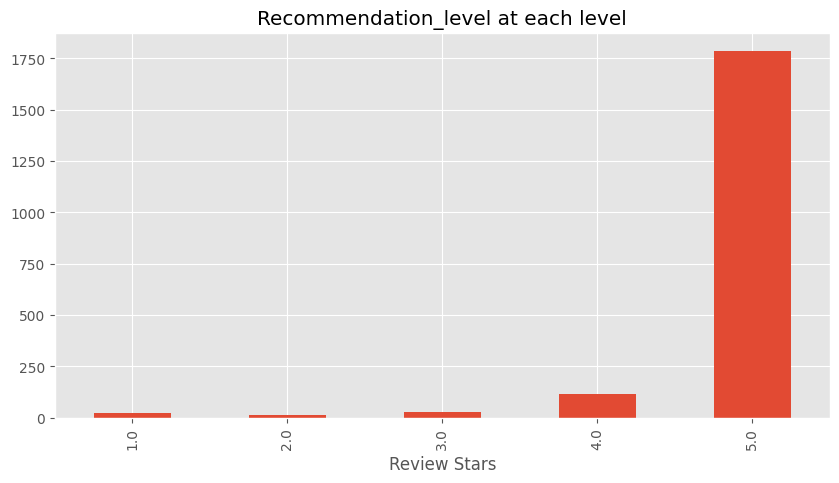

In [ ]:
#we see the amount of cusomers that are likely to recommend
ax = df['recommendation_level'].value_counts().sort_index() \
    .plot(kind='bar',
          title='Recommendation_level at each level',
          figsize=(10, 5))
ax.set_xlabel('Review Stars')
# Save the plot as a PNG image
plt.savefig('Recommendation_level.png')
plt.show()

In [ ]:
#Calculate value counts and percentages
value_counts = df['recommendation_level'].value_counts()
total_entries = len(df)
percentages = (value_counts / total_entries) * 100

# Print value counts and percentages
for category, count in value_counts.items():
    percentage = percentages[category]
    print(f"Category: {category} | Count: {count} | Percentage: {percentage:.2f}%")

Category: 5.0 | Count: 1786 | Percentage: 90.89%
Category: 4.0 | Count: 114 | Percentage: 5.80%
Category: 3.0 | Count: 27 | Percentage: 1.37%
Category: 1.0 | Count: 23 | Percentage: 1.17%
Category: 2.0 | Count: 15 | Percentage: 0.76%


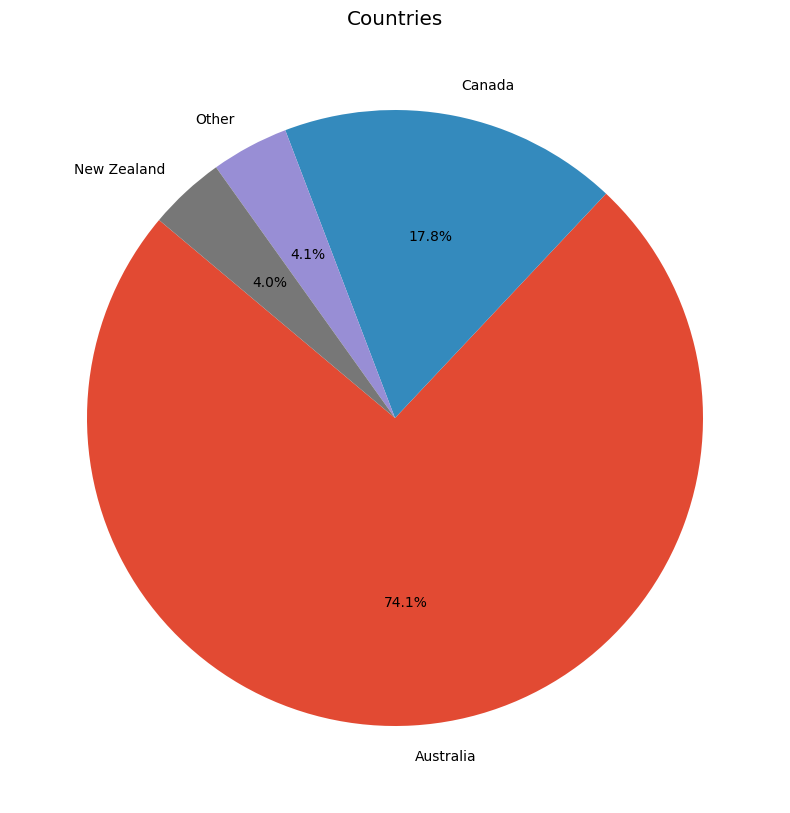

In [ ]:
#we create a pie chart to view the percentages in country
# Calculate value counts
value_counts = df['Country'].value_counts()

# Plot a pie chart
plt.figure(figsize=(10, 10))
plt.pie(value_counts, labels=value_counts.index, autopct='%1.1f%%', startangle=140)
plt.title("Countries")
# Save the plot as a PNG image
plt.savefig('country_distributions.png')
plt.show()


# **Sentimental analysis**
In this section we will look at the sentiment in each "comment" and try to categorise it under positive,neutral and negative.


In [ ]:
example = df['comments'][9]
print(example)

I love the staff, iconic shape, recycled materials, colours available (Bloody Mary my favourite), light weight frames, excellent service and how quick my order was completed.


In [ ]:
# Run for Roberta Model
encoded_text = tokenizer(example, return_tensors='pt')
output = model(**encoded_text)
scores = output[0][0].detach().numpy()
scores = softmax(scores)
scores_dict = {
    'roberta_neg' : scores[0],
    'roberta_neu' : scores[1],
    'roberta_pos' : scores[2]
}
print(scores_dict)

{'roberta_neg': 0.0023803697, 'roberta_neu': 0.01016574, 'roberta_pos': 0.9874538}


In [ ]:
#place as a function
def polarity_scores_roberta(example):
    encoded_text = tokenizer(example, return_tensors='pt')
    output = model(**encoded_text)
    scores = output[0][0].detach().numpy()
    scores = softmax(scores)
    scores_dict = {
        'roberta_neg' : scores[0],
        'roberta_neu' : scores[1],
        'roberta_pos' : scores[2]
    }
    return scores_dict

In [ ]:
#sentimental analysis of each comment into a dictionary
res = {}
for i, row in tqdm(df.iterrows(), total=len(df)):
    try:
        text = row['comments']
        myid = row['Id']
        roberta_result = polarity_scores_roberta(text)
        res[myid] = roberta_result
    except RuntimeError:
        print(f'Broke for id {myid}')

 37%|███▋      | 730/1965 [02:51<03:34,  5.75it/s]

Broke for id 779


100%|██████████| 1965/1965 [07:02<00:00,  4.65it/s]


In [ ]:
result_df = pd.DataFrame(res).T
result_df = result_df.reset_index().rename(columns={'index': 'Id'})
result_df = result_df.merge(df, how='left')

In [ ]:
# Drop the desired column (e.g., column 'B')
result_df = result_df.drop(columns=['Id'])

In [ ]:
result_df.head()

,roberta_neg,roberta_neu,roberta_pos,Location_id,Country,About,Favour,comments,Satisfaction level,recommendation_level
0,0.798665,0.178177,0.023158,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0
1,0.007219,0.057529,0.935252,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0
2,0.002067,0.067462,0.930471,NILL,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0
3,0.002051,0.057350,0.940599,NILL,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0
4,0.654623,0.307441,0.037936,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0


In [ ]:
# Function to determine the label based on the highest value among columns 'roberta_neg', 'roberta_neu', and 'roberta_pos'
def determine_label(row):
    highest_value = max(row['roberta_neg'], row['roberta_neu'], row['roberta_pos'])
    if highest_value == row['roberta_pos']:
        return 'positive'
    elif highest_value == row['roberta_neg']:
        return 'negative'
    elif highest_value == row['roberta_neu']:
        return 'neutral'
    else:
        return 'unknown'

# Apply the function to each row and store the results in a new column 'sentiment'
result_df['sentiment'] = result_df.apply(determine_label, axis=1)

# Print the DataFrame with the new 'sentiment' colum
result_df.head(5)

,roberta_neg,roberta_neu,roberta_pos,Location_id,Country,About,Favour,comments,Satisfaction level,recommendation_level,sentiment
0,0.798665,0.178177,0.023158,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0,negative
1,0.007219,0.057529,0.935252,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0,positive
2,0.002067,0.067462,0.930471,NILL,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0,positive
3,0.002051,0.057350,0.940599,NILL,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0,positive
4,0.654623,0.307441,0.037936,NILL,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0,negative


In [ ]:
#drop unnecessary columns
columns_to_drop = [ 'roberta_neg', 'roberta_neu','roberta_pos','Location_id']
result_df.drop(columns=columns_to_drop, inplace=True)
result_df.head()

,Country,About,Favour,comments,Satisfaction level,recommendation_level,sentiment
0,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0,negative
1,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0,positive
2,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0,positive
3,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0,positive
4,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0,negative


In [ ]:
# we look at the distribution of sentiments
# Count the occurrences of each sentiment category
sentiment_counts = result_df['sentiment'].value_counts()
# Create the bar chart using Plotly
fig = go.Figure()
fig.add_trace(go.Bar(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
    marker_color=['green', 'red', 'blue']
))

fig.update_layout(
    title='Sentiment Distribution',
    xaxis=dict(title='Sentiment'),
    yaxis=dict(title='Number of Occurrences')
)

# Show the plot
fig.show()
# Save the plot as an image file (e.g., PNG)
output_filename = 'sentiment_plot.png'
plt.savefig(output_filename)

<Figure size 640x480 with 0 Axes>

In [ ]:
#check distribution of sentiment accrording to regions
# Group and count the sentiment categories for each country
sentiment_counts = result_df.groupby(['Country', 'sentiment']).size().unstack(fill_value=0)

# Calculate the total count of sentiments for each country
sentiment_counts['Total'] = sentiment_counts.sum(axis=1)

# Create the Plotly bar chart
fig = go.Figure()

for sentiment in sentiment_counts.columns:
    if sentiment != 'Total':
        fig.add_trace(go.Bar(
            x=sentiment_counts.index,
            y=sentiment_counts[sentiment],
            name=sentiment,
        ))

fig.update_layout(
    title="Sentiment Distribution across Countries",
    xaxis_title="Country",
    yaxis_title="Count",
    barmode='stack',  # 'stack' for stacked bar chart
    showlegend=True,
    legend=dict(title="Sentiment"),
    height=600,  # Set the figure height
)
# Save the plot as a PNG image
plt.savefig('Sentiment_across countries.png')
fig.show()


<Figure size 640x480 with 0 Axes>

# **Text classification**
In this section our aim will be to make general topics from all the comments made and try to classify them into specific topics

In [ ]:
# we start with the comment section

# Create TF-IDF vectorizer
vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(result_df['comments'])

# Specify the number of topics
num_topics = 5

# Specify the maximum number of top words per topic
max_top_words = 5

# Perform NMF for topic extraction
nmf_model = NMF(n_components=num_topics, random_state=42)
nmf_matrix = nmf_model.fit_transform(tfidf_matrix)

# Get feature names from the vectorizer
feature_names = vectorizer.get_feature_names_out()

# Initialize a set to keep track of selected words
selected_words = set()

# Print the top words for each topic
for topic_idx, topic in enumerate(nmf_model.components_):
    top_words_idx = topic.argsort()[-max_top_words:][::-1]
    top_words = [feature_names[idx] for idx in top_words_idx if feature_names[idx] not in selected_words]
    selected_words.update(top_words)  # Add selected words to the set
    print(f"Topic {topic_idx}: {', '.join(top_words)}")

# Assign each comment to one of the topics
topic_indices = nmf_matrix.argmax(axis=1)
result_df['assigned_topic_comment'] = topic_indices

# Print the assigned topics for each comment
#for index, row in df.iterrows():
 #   print(f"Comment: {row['comments']} | Assigned Topic: Topic {row['assigned_topic']}")


Topic 0: nan, fantastic, product, price, store
Topic 1: great, service, experience, staff
Topic 2: glasses, love, dresden, frames, new
Topic 3: excellent, customer, professional
Topic 4: friendly, helpful, knowledgeable


In [ ]:
# we start with the About	 section

# Create TF-IDF vectorizer
vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(result_df['About'])

# Specify the number of topics
num_topics = 5

# Specify the maximum number of top words per topic
max_top_words = 5

# Perform NMF for topic extraction
nmf_model = NMF(n_components=num_topics, random_state=42)
nmf_matrix = nmf_model.fit_transform(tfidf_matrix)

# Get feature names from the vectorizer
feature_names = vectorizer.get_feature_names_out()

# Initialize a set to keep track of selected words
selected_words = set()

# Print the top words for each topic
for topic_idx, topic in enumerate(nmf_model.components_):
    top_words_idx = topic.argsort()[-max_top_words:][::-1]
    top_words = [feature_names[idx] for idx in top_words_idx if feature_names[idx] not in selected_words]
    selected_words.update(top_words)  # Add selected words to the set
    print(f"Topic {topic_idx}: {', '.join(top_words)}")

# Assign each comment to one of the topics
topic_indices = nmf_matrix.argmax(axis=1)
result_df['assigned_topic_About'] = topic_indices

# Print the assigned topics for each comment
#for index, row in df.iterrows():
 #   print(f"Comment: {row['comments']} | Assigned Topic: Topic {row['assigned_topic']}")

Topic 0: nill, media, social, affordability, expert
Topic 1: recommended, colleague, friend, friends, family
Topic 2: stores, physical, try, different
Topic 3: engine, google, yahoo, search
Topic 4: customer, dresden, vision, glasses, repeat


In [ ]:
# we start with the Favour section

# Create TF-IDF vectorizer
vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(result_df['Favour'])

# Specify the number of topics
num_topics = 5

# Specify the maximum number of top words per topic
max_top_words = 5

# Perform NMF for topic extraction
nmf_model = NMF(n_components=num_topics, random_state=42)
nmf_matrix = nmf_model.fit_transform(tfidf_matrix)

# Get feature names from the vectorizer
feature_names = vectorizer.get_feature_names_out()

# Initialize a set to keep track of selected words
selected_words = set()

# Print the top words for each topic
for topic_idx, topic in enumerate(nmf_model.components_):
    top_words_idx = topic.argsort()[-max_top_words:][::-1]
    top_words = [feature_names[idx] for idx in top_words_idx if feature_names[idx] not in selected_words]
    selected_words.update(top_words)  # Add selected words to the set
    print(f"Topic {topic_idx}: {', '.join(top_words)}")

# Assign each comment to one of the topics
topic_indices = nmf_matrix.argmax(axis=1)
result_df['assigned_topic_Favour'] = topic_indices

# Print the assigned topics for each comment
#for index, row in df.iterrows():
 #   print(f"Comment: {row['comments']} | Assigned Topic: Topic {row['assigned_topic']}")

Topic 0: nill, love, affordability, products, expert
Topic 1: sizes, wide, range, colours, ready
Topic 2: recycled, sustainable
Topic 3: price, value, store
Topic 4: 10, warranty, year, frame, convenience


In [ ]:
result_df.head()

,Country,About,Favour,comments,Satisfaction level,recommendation_level,sentiment,assigned_topic_comment,assigned_topic_About,assigned_topic_Favour
0,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0,negative,4,1,2
1,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0,positive,3,1,1
2,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0,positive,2,4,1
3,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0,positive,2,4,1
4,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0,negative,2,1,1


In [ ]:
#Map each column to a specific topic
#Comment

# Define the mapping dictionary
mapping = {
    1: 'price',  # fantastic, product, price, store
    2: 'staff',  # great, service, experience, staff
    3: 'product (frames,glasses,color)',  # glasses, love, dresden, frames, new
    4: 'staff',  # excellent, customer, professional
    5: 'staff'   # friendly, helpful, knowledgeable


}

# Map the values in the 'Ratings' column to topics
result_df['Topics_Comment'] = result_df['assigned_topic_comment'].map(mapping)


In [ ]:
#Map each column to a specific topic
#About

# Define the mapping dictionary
mapping = {
    1 : 'social media' , #nill, media, social, affordability, expert
    2 :'friend,family' ,  #recommended, colleague, friend, friends, family
    3 :'physical store' , #stores, physical, try, different
    4 : 'social media' , #engine, google, yahoo, search
    5 : 'Customer'#customer, dresden, vision, glasses, repeat
}

# Map the values in the 'Ratings' column to topics
result_df['Topics_About'] = result_df['assigned_topic_About'].map(mapping)

In [ ]:
#Map each column to a specific topic
#Favour

# Define the mapping dictionary
mapping = {
    1:'affordability',#nill, love, affordability, products, expert
    2: 'Range(color,sizes)',#sizes, wide, range, colours, ready
    3:'sustainable', #recycled, sustainable
    4: 'price',#price, value, store
    5: 'warranty and frames(convinence)'#10, warranty, year, frame, convenience
}

# Map the values in the 'Ratings' column to topics
result_df['Topics_Favour'] = result_df['assigned_topic_Favour'].map(mapping)

In [ ]:
columns_to_drop = ['assigned_topic_comment', 'assigned_topic_About','assigned_topic_Favour',]
result_df = result_df.drop(columns=columns_to_drop)

In [ ]:
result_df.head()


,Country,About,Favour,comments,Satisfaction level,recommendation_level,sentiment,Topics_Comment,Topics_About,Topics_Favour
0,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0,negative,staff,social media,"Range(color,sizes)"
1,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0,positive,"product (frames,glasses,color)",social media,affordability
2,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0,positive,staff,social media,affordability
3,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0,positive,staff,social media,affordability
4,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0,negative,staff,social media,affordability


In [ ]:
# Define the file path to your desktop
file_path = "C:\Desktop\Final_dresden.xlsx"

# Save the DataFrame to an Excel file on your desktop
result_df.to_excel(file_path, index=False)

print("Excel file saved successfully.")

Excel file saved successfully.


# **Case studies and scenarios**
In this section we will look at different scenarios to get more insight about the data also we will add weights to topics so we can use integar optimization to prioritize topics moving forward. we will also apply several statistical testing in this section.

In [ ]:
result_df.head()

,Country,About,Favour,comments,Satisfaction level,recommendation_level,sentiment,Topics_Comment,Topics_About,Topics_Favour
0,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0,negative,staff,social media,"Range(color,sizes)"
1,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0,positive,"product (frames,glasses,color)",social media,affordability
2,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0,positive,staff,social media,affordability
3,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0,positive,staff,social media,affordability
4,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0,negative,staff,social media,affordability


#**General overview**
We begin our case study by analyzing the general layout and questions in the data.
1. What is the distribution of topics?
2. what topics appear most in each sentiment i.e Positive,negative and neutral?
3. what topic had the highest level of satisfaction and recommendation levels?


In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts = result_df['Topics_Comment'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topic comment', xaxis_title='comments', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('Topics_overall')
fig.show()


<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go


# Calculate value counts for each sentiment-topic combination
sentiments = ['positive', 'negative', 'neutral']
fig = make_subplots(rows=1, cols=len(sentiments), subplot_titles=sentiments, specs=[[{'type': 'pie'}]*len(sentiments)])

for i, sentiment in enumerate(sentiments):
    sentiment_data = result_df[result_df['sentiment'] == sentiment]
    value_counts = sentiment_data['Topics_Comment'].value_counts()

    fig.add_trace(go.Pie(labels=value_counts.index, values=value_counts.values, title=sentiment + ' Sentiment'), row=1, col=i+1)

fig.update_layout(title_text="Topics by Sentiment")
# Save the plot as a PNG image
plt.savefig('sentiments_overall.png')
fig.show()


<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px

# Calculate value counts for each satisfaction level-topic combination
value_counts = result_df.groupby(['Satisfaction level', 'Topics_Comment']).size().reset_index(name='Count')

# Create a grouped bar chart using Plotly
fig = px.bar(value_counts, x='Satisfaction level', y='Count', color='Topics_Comment',
             labels={'Satisfaction_Level': 'Satisfaction Level', 'Count': 'Count'},
             title='Topics by Satisfaction Level')
# Save the plot as a PNG image
plt.savefig('Satisfaction_levels_overall.png')
fig.show()


<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px

# Calculate value counts for each satisfaction level-topic combination
value_counts = result_df.groupby(['recommendation_level', 'Topics_Comment']).size().reset_index(name='Count')

# Create a grouped bar chart using Plotly
fig = px.bar(value_counts, x='recommendation_level', y='Count', color='Topics_Comment',
             labels={'recommendation_level': 'recommendation_level', 'Count': 'Count'},
             title='Recommendation level')
# Save the plot as a PNG image
plt.savefig('Recommendation level_overall.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
#lets look at the negative comments
negative_data = result_df[result_df['sentiment'] == 'negative']
docs = negative_data.comments.tolist()
docs[70]

'Not so good really. Ordered new lenses which were posted promptly -yay! But one was the wrong size and broke the frame. My partner took them in the next day to the Newtown store and tried to order sunnies but was curtly told he was 11hrs late for the special deal so tough luck. Never mind that I have to wait more than 11?hours for my new lens!!'

In [ ]:
#All negative comments
docs

['Admin organisation at Brunswick could be a bit better. It has been confusing to deal with all the different staff & miscommunication has hampered my transactions. ',
 'I noticed the shipping is more expensive on the Dresden go site compared to the Dresden site. Also the option of mixing the colours up is not available. I prefer to call and get the better deal from Dresden rather than Dresden go',
 'Nothing as nothing compares to Dresden.',
 'Can’t get a reply on chat to check order status at 10:20am in Sydney ',
 'When I ring to make an appointment your recorded, or bot, messages are almost unintelligible. They’re extremely frustrating and would be enough to make me hang up and go elsewhere except that I’ve found your optometrists to be so good. If I were ringing for the first time you would have lost me as a customer.',
 "Simply stream line the process- there's a bit too much drama for my liking- a bit of hype .",
 'The exam was technically fine but the “bedside manner” of the optom

In [ ]:
#lets look at the Positive comments
positive_data = result_df[result_df['sentiment'] == 'positive']
docs_pos = positive_data.comments.tolist()
docs_pos[84]

'Great product.'

In [ ]:
docs_pos

['Excellent service and great product ',
 'The glasses are comfortable and contemporary.  You can change the arms around for colours which is handy.',
 'I have been wearing Dresden glasses for more than five years. I believe in what their doing with recycled materials and their sustainability efforts.  I recommend Dresden to all of my friends and family.',
 "The ordering process for prescription glasses wasn't straight forward and the first two pair of prescription glasses I received had mistakes in the lenses meaning that I had to return my glasses and wait for the optometrist I visited to contact Dresden to get the details sorted. The problems were with Dresden not my optometrist so maybe a better check of details would have made the process smoother. Once the proper lenses were in my frames, everything seemed much better. I get many compliments on my glasses and am very glad to be buying products made sustainably. ",
 'Loved the experience, will be back for new glasses ',
 'No impro

In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts = result_df['Topics_About'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topics_About', xaxis_title='About', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('About_overall.png')
fig.show()


<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts = result_df['Topics_Favour'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topics_Favour', xaxis_title='Favour', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('Favour_overall.png')
fig.show()

<Figure size 640x480 with 0 Axes>

#**Region Based Approach**
in this section we will bring our case study to a region based study. we will look at regions and analyse the comments and sentiments accordingly.
1. Australia
2. New zealand
3. Canada

###**Questions to be answered accordingly in each region**
1. What is the distribution of topicsin each region?
2. what topics appear most in each sentiment i.e Positive,negative and neutral in each region?
3. what topic had the highest level of satisfaction and recommendation levels in each region?

#**Australia**
in this section we look at results unique to australia.

In [ ]:
#Filter out australia
AU_df = result_df[result_df['Country'] == 'Australia']
AU_df.head()

,Country,About,Favour,comments,Satisfaction level,recommendation_level,sentiment,Topics_Comment,Topics_About,Topics_Favour
0,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0,negative,staff,social media,"Range(color,sizes)"
1,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0,positive,"product (frames,glasses,color)",social media,affordability
2,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0,positive,staff,social media,affordability
3,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0,positive,staff,social media,affordability
4,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0,negative,staff,social media,affordability


In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts =AU_df['Topics_Comment'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topic comment', xaxis_title='comments', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('Comment_Au.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go


# Calculate value counts for each sentiment-topic combination
sentiments = ['positive', 'negative', 'neutral']
fig = make_subplots(rows=1, cols=len(sentiments), subplot_titles=sentiments, specs=[[{'type': 'pie'}]*len(sentiments)])

for i, sentiment in enumerate(sentiments):
    sentiment_data = AU_df[AU_df['sentiment'] == sentiment]
    value_counts = sentiment_data['Topics_Comment'].value_counts()

    fig.add_trace(go.Pie(labels=value_counts.index, values=value_counts.values, title=sentiment + ' Sentiment'), row=1, col=i+1)

fig.update_layout(title_text="Topics by Sentiment")
# Save the plot as a PNG image
plt.savefig('Sentiment_AU.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px

# Calculate value counts for each satisfaction level-topic combination
value_counts = AU_df.groupby(['Satisfaction level', 'Topics_Comment']).size().reset_index(name='Count')

# Create a grouped bar chart using Plotly
fig = px.bar(value_counts, x='Satisfaction level', y='Count', color='Topics_Comment',
             labels={'Satisfaction_Level': 'Satisfaction Level', 'Count': 'Count'},
             title='Topics by Satisfaction Level')
# Save the plot as a PNG image
plt.savefig('Satisfaction_AU.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px

# Calculate value counts for each satisfaction level-topic combination
value_counts = AU_df.groupby(['recommendation_level', 'Topics_Comment']).size().reset_index(name='Count')

# Create a grouped bar chart using Plotly
fig = px.bar(value_counts, x='recommendation_level', y='Count', color='Topics_Comment',
             labels={'recommendation_level': 'recommendation_level', 'Count': 'Count'},
             title='Count of Topics by Recommendation level')
# Save the plot as a PNG image
plt.savefig('recommendation_AU.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts = AU_df['Topics_About'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topics_About', xaxis_title='About', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('About_AU.png')
fig.show()


<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts = AU_df['Topics_Favour'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topics_Favour', xaxis_title='Favour', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('Favour_AU.png')
fig.show()

<Figure size 640x480 with 0 Axes>

# **CANADA**
in this section we look ar results unique to canada.


In [ ]:
#Filter out Canada
CA_df = result_df[result_df['Country'] == 'Canada']
CA_df.head()

,Country,About,Favour,comments,Satisfaction level,recommendation_level,sentiment,Topics_Comment,Topics_About,Topics_Favour
37,Canada,"Sunlife,Love your products",nan,nan,4.0,5.0,neutral,NaN,social media,price
38,Canada,"Recommended by a friend or colleague,Love your...",nan,I am very happy with friendly and knowledgeabl...,5.0,5.0,positive,staff,social media,price
39,Canada,"Our physical stores,Affordability - Wanting ...",nan,I saw Dr. Jana Parasmeswaran and had a very go...,5.0,5.0,positive,staff,"friend,family",price
40,Canada,"Our physical stores , wanted to try somwthing ...",nan,nan,5.0,5.0,neutral,NaN,"friend,family",price
41,Canada,"Recommended by a friend or colleague,Recommend...",nan,nan,5.0,5.0,neutral,NaN,social media,price


In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts =CA_df['Topics_Comment'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topic comment', xaxis_title='comments', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('Topic_CA.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go


# Calculate value counts for each sentiment-topic combination
sentiments = ['positive', 'negative', 'neutral']
fig = make_subplots(rows=1, cols=len(sentiments), subplot_titles=sentiments, specs=[[{'type': 'pie'}]*len(sentiments)])

for i, sentiment in enumerate(sentiments):
    sentiment_data = CA_df[CA_df['sentiment'] == sentiment]
    value_counts = sentiment_data['Topics_Comment'].value_counts()

    fig.add_trace(go.Pie(labels=value_counts.index, values=value_counts.values, title=sentiment + ' Sentiment'), row=1, col=i+1)

fig.update_layout(title_text="Topics by Sentiment")
# Save the plot as a PNG image
plt.savefig('Sentiment_CA.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px

# Calculate value counts for each satisfaction level-topic combination
value_counts = CA_df.groupby(['Satisfaction level', 'Topics_Comment']).size().reset_index(name='Count')

# Create a grouped bar chart using Plotly
fig = px.bar(value_counts, x='Satisfaction level', y='Count', color='Topics_Comment',
             labels={'Satisfaction_Level': 'Satisfaction Level', 'Count': 'Count'},
             title='Topics by Satisfaction Level')
# Save the plot as a PNG image
plt.savefig('Satisfaction_CA.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px

# Calculate value counts for each satisfaction level-topic combination
value_counts = CA_df.groupby(['recommendation_level', 'Topics_Comment']).size().reset_index(name='Count')

# Create a grouped bar chart using Plotly
fig = px.bar(value_counts, x='recommendation_level', y='Count', color='Topics_Comment',
             labels={'recommendation_level': 'recommendation_level', 'Count': 'Count'},
             title='Topics by Recommendation level')
# Save the plot as a PNG image
plt.savefig('Recommendation_CA.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts = CA_df['Topics_About'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topics_About', xaxis_title='About', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('About_CA.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts = AU_df['Topics_Favour'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topics_Favour', xaxis_title='Favour', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('Favour_CA.png')
fig.show()

<Figure size 640x480 with 0 Axes>

# **New zealand**
In this section we look at results unique to New zealand

In [ ]:
#Filter out New zealand
NZ_df = result_df[result_df['Country'] == 'New Zealand']
NZ_df.head()

,Country,About,Favour,comments,Satisfaction level,recommendation_level,sentiment,Topics_Comment,Topics_About,Topics_Favour
964,New Zealand,NILL,NILL,nan,5.0,5.0,neutral,NaN,NaN,NaN
965,New Zealand,NILL,NILL,sales person at Union Station Toronto Desden...,5.0,5.0,positive,staff,NaN,NaN
966,New Zealand,NILL,NILL,Very convenient location and very helpful staff.,5.0,5.0,positive,staff,NaN,NaN
967,New Zealand,NILL,NILL,Just popped in for a pair of replacement reade...,5.0,5.0,positive,staff,NaN,NaN
968,New Zealand,NILL,NILL,Great value and lots of fun choices. Very hel...,5.0,5.0,positive,staff,NaN,NaN


In [ ]:
import pandas as pd
import plotly.express as px
# Calculate value counts
value_counts =NZ_df['Topics_Comment'].value_counts()

# Create a bar chart using Plotly
fig = px.bar(x=value_counts.index, y=value_counts.values, labels={'x': 'Category', 'y': 'Count'})
fig.update_layout(title='Topic comment', xaxis_title='comments', yaxis_title='Count')
# Save the plot as a PNG image
plt.savefig('Topic_NZ.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go


# Calculate value counts for each sentiment-topic combination
sentiments = ['positive', 'negative', 'neutral']
fig = make_subplots(rows=1, cols=len(sentiments), subplot_titles=sentiments, specs=[[{'type': 'pie'}]*len(sentiments)])

for i, sentiment in enumerate(sentiments):
    sentiment_data = NZ_df[NZ_df['sentiment'] == sentiment]
    value_counts = sentiment_data['Topics_Comment'].value_counts()

    fig.add_trace(go.Pie(labels=value_counts.index, values=value_counts.values, title=sentiment + ' Sentiment'), row=1, col=i+1)

fig.update_layout(title_text="Topics by Sentiment")
# Save the plot as a PNG image
plt.savefig('Sentiment_NZ.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px

# Calculate value counts for each satisfaction level-topic combination
value_counts = NZ_df.groupby(['Satisfaction level', 'Topics_Comment']).size().reset_index(name='Count')

# Create a grouped bar chart using Plotly
fig = px.bar(value_counts, x='Satisfaction level', y='Count', color='Topics_Comment',
             labels={'Satisfaction_Level': 'Satisfaction Level', 'Count': 'Count'},
             title='Topics by Satisfaction Level')
# Save the plot as a PNG image
plt.savefig('Satisfaction_NZ.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import plotly.express as px

# Calculate value counts for each satisfaction level-topic combination
value_counts = NZ_df.groupby(['recommendation_level', 'Topics_Comment']).size().reset_index(name='Count')

# Create a grouped bar chart using Plotly
fig = px.bar(value_counts, x='recommendation_level', y='Count', color='Topics_Comment',
             labels={'recommendation_level': 'recommendation_level', 'Count': 'Count'},
             title='Recommendation level')
# Save the plot as a PNG image
plt.savefig('Recommendation_NZ.png')
fig.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
#Both the About and Favour columns are empty due to lack of data available

# **Scaling each topic**
In this final section we will look at each topic in comment,favour and about and we assign weights to each of them, then we try to optimize the customer satisfaction considering where the comapnay should invest more on.


In [ ]:
result_df.head()

,Country,About,Favour,comments,Satisfaction level,recommendation_level,sentiment,Topics_Comment,Topics_About,Topics_Favour
0,Australia,Recommended by a friend or colleague,Sustainable & recycled products,Admin organisation at Brunswick could be a bit...,4.0,4.0,negative,staff,social media,"Range(color,sizes)"
1,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Value and ...,Excellent service and great product,5.0,5.0,positive,"product (frames,glasses,color)",social media,affordability
2,Australia,I’m a Dresden Vision customer already,"Ready to go, no prescription needed - Sustai...",The glasses are comfortable and contemporary. ...,5.0,5.0,positive,staff,social media,affordability
3,Australia,I’m a Dresden Vision customer already,Sustainable & recycled products - Value and ...,I have been wearing Dresden glasses for more t...,5.0,5.0,positive,staff,social media,affordability
4,Australia,Recommended by a friend or colleague,Sustainable & recycled products - Wide range...,I noticed the shipping is more expensive on th...,5.0,4.0,negative,staff,social media,affordability


In [ ]:
import pandas as pd
import math
# Calculate value counts for each class
class_counts = result_df['Topics_Comment'].value_counts()

# Calculate percentages
total_samples = len(result_df)
class_percentages = class_counts / total_samples * 100
# Print the percentages
for class_name, percentage in class_percentages.items():
     rounded_percentage = math.floor(percentage)
     print(f'{class_name}: {rounded_percentage}%')


staff: 57%
product (frames,glasses,color): 10%
price: 9%


In [ ]:
# Calculate value counts for each class
class_counts = result_df['Topics_Favour'].value_counts()
# Calculate percentages
total_samples = len(result_df)
class_percentages = class_counts / total_samples * 100
# Print the percentages
for class_name, percentage in class_percentages.items():
     rounded_percentage = math.floor(percentage)
     print(f'{class_name}: {rounded_percentage}%')

affordability: 8%
Range(color,sizes): 6%
price: 5%
sustainable: 1%


In [ ]:
# Calculate value counts for each class
class_counts = result_df['Topics_About'].value_counts()

# Calculate percentages
total_samples = len(result_df)
class_percentages = class_counts / total_samples * 100
# Print the percentages
for class_name, percentage in class_percentages.items():
     rounded_percentage = math.floor(percentage)
     print(f'{class_name}: {rounded_percentage}%')

social media: 14%
friend,family: 5%
physical store: 2%


# Final weights of each topic generally includes
The topics are further defined into the follwoing with weights:

1.**Customer experience:** After reviewing all comments it is apparent that the customer experience is the biggest factor in the minds of the customers both from negaive and positive comments.in this evaluation we consider any praise or cmplaint towards attitude of customers, response time and feel from customers and  response time.

2.**Product:** This will also be considered and joined togther from several groups of topics, from our analysis we bring together the fucntionality of product as well as the delivery time of product.

3.**price:**The price depends heavily on the customer experience as well as the quality of the product although the price is affordable for most customers it is also apparent that the product and customer experience plays a heavy role.

we will use interger optimization in different scenarios and see the best case moving forward.

